Input folder: d:\Sem_5\DSIP\Practical_Code\OEP_10
Output folder: d:\Sem_5\DSIP\Practical_Code\OEP_10\Output

Processing: Picture1.png


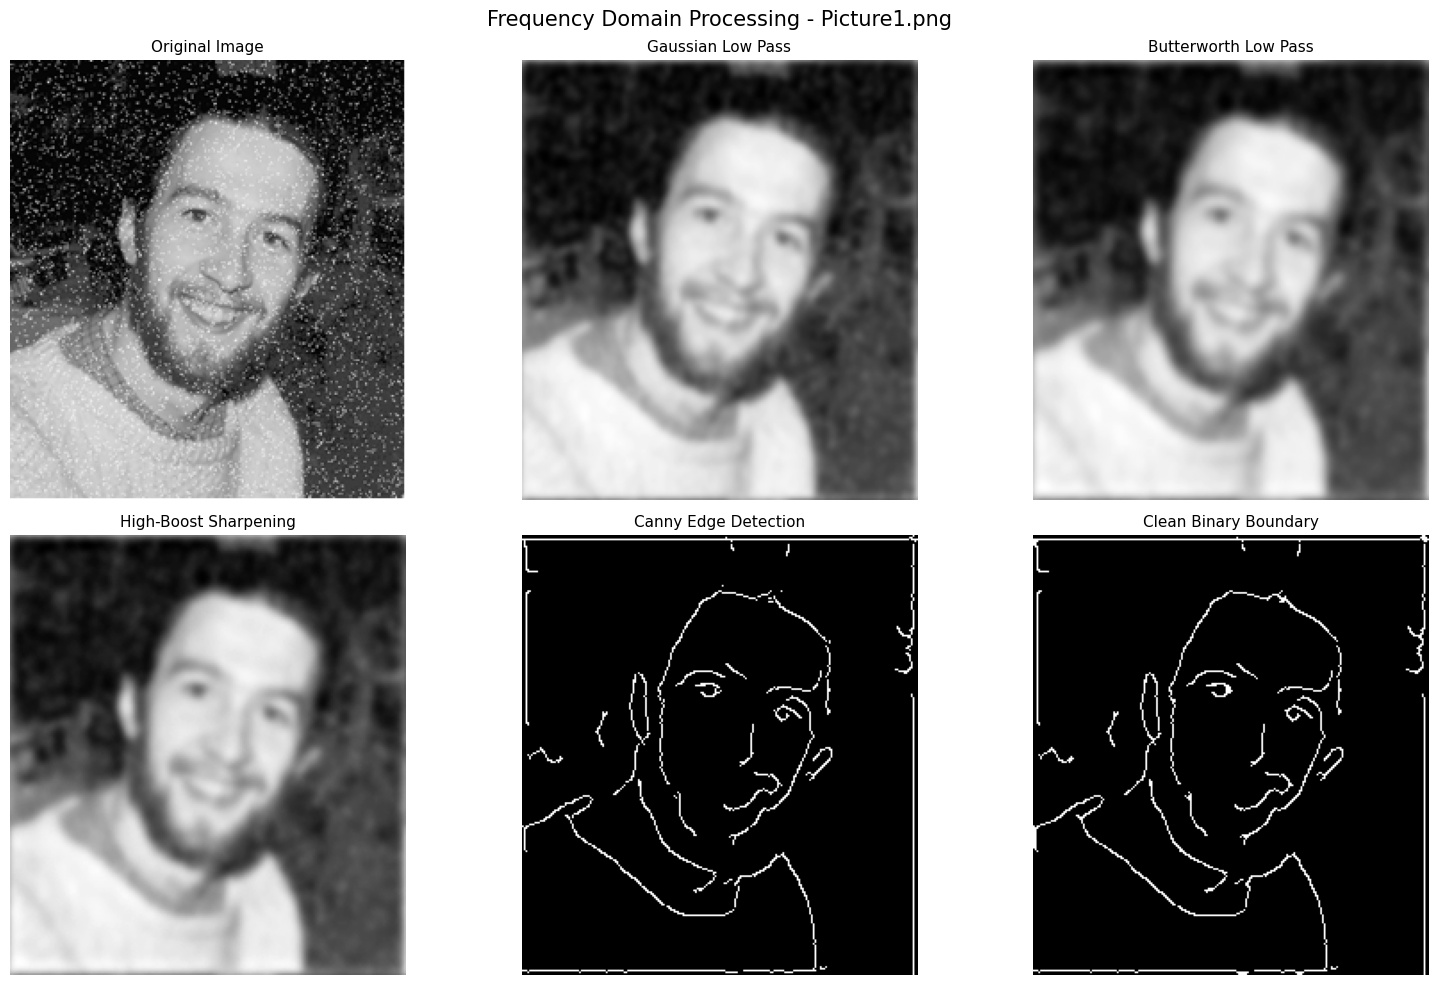

Completed: Picture1.png

Processing: Picture2.png


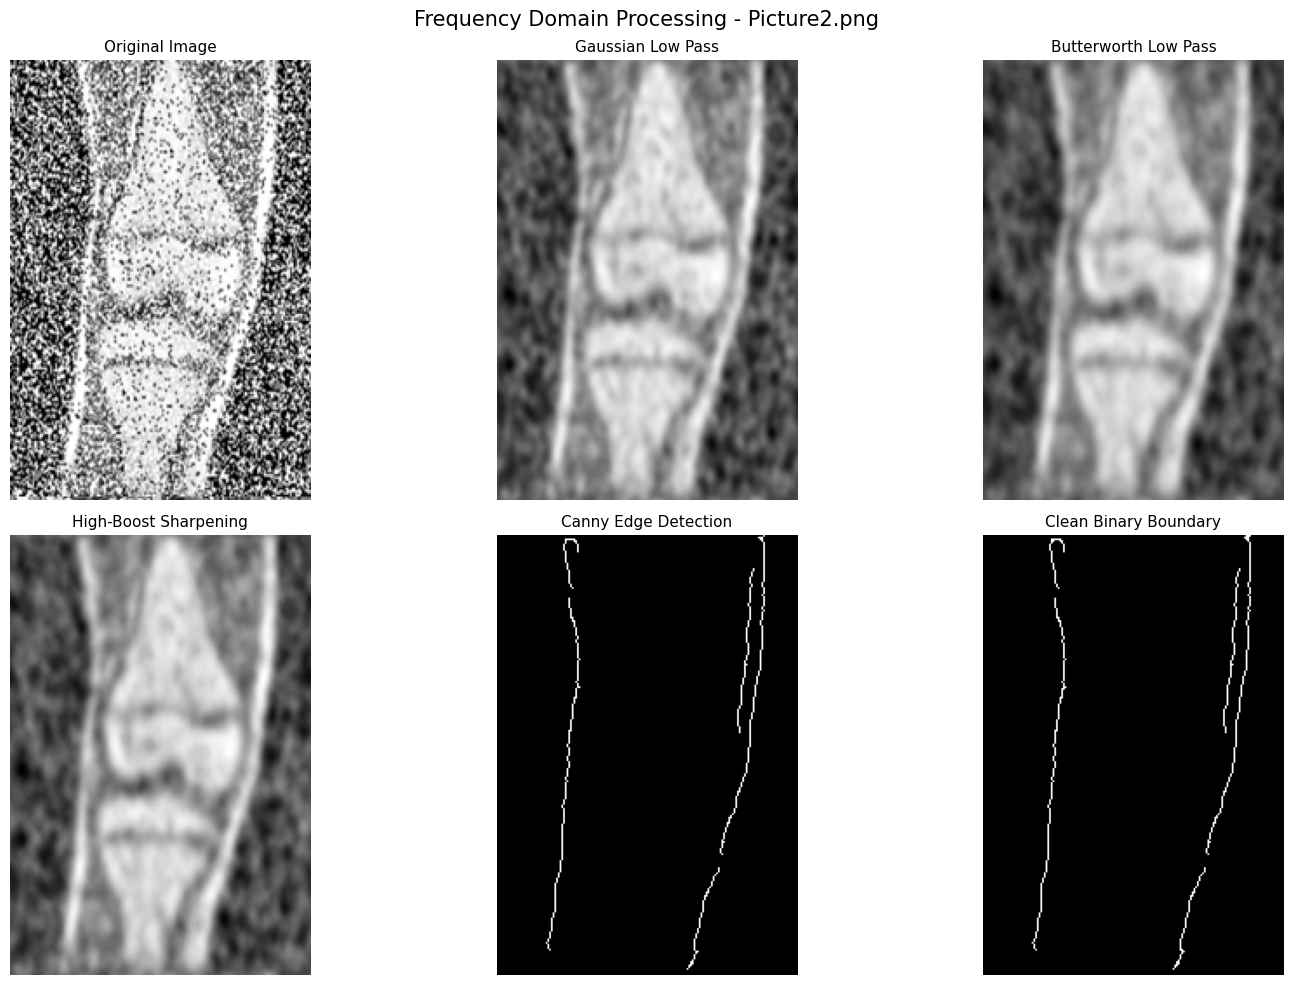

Completed: Picture2.png

Processing: Picture3.png


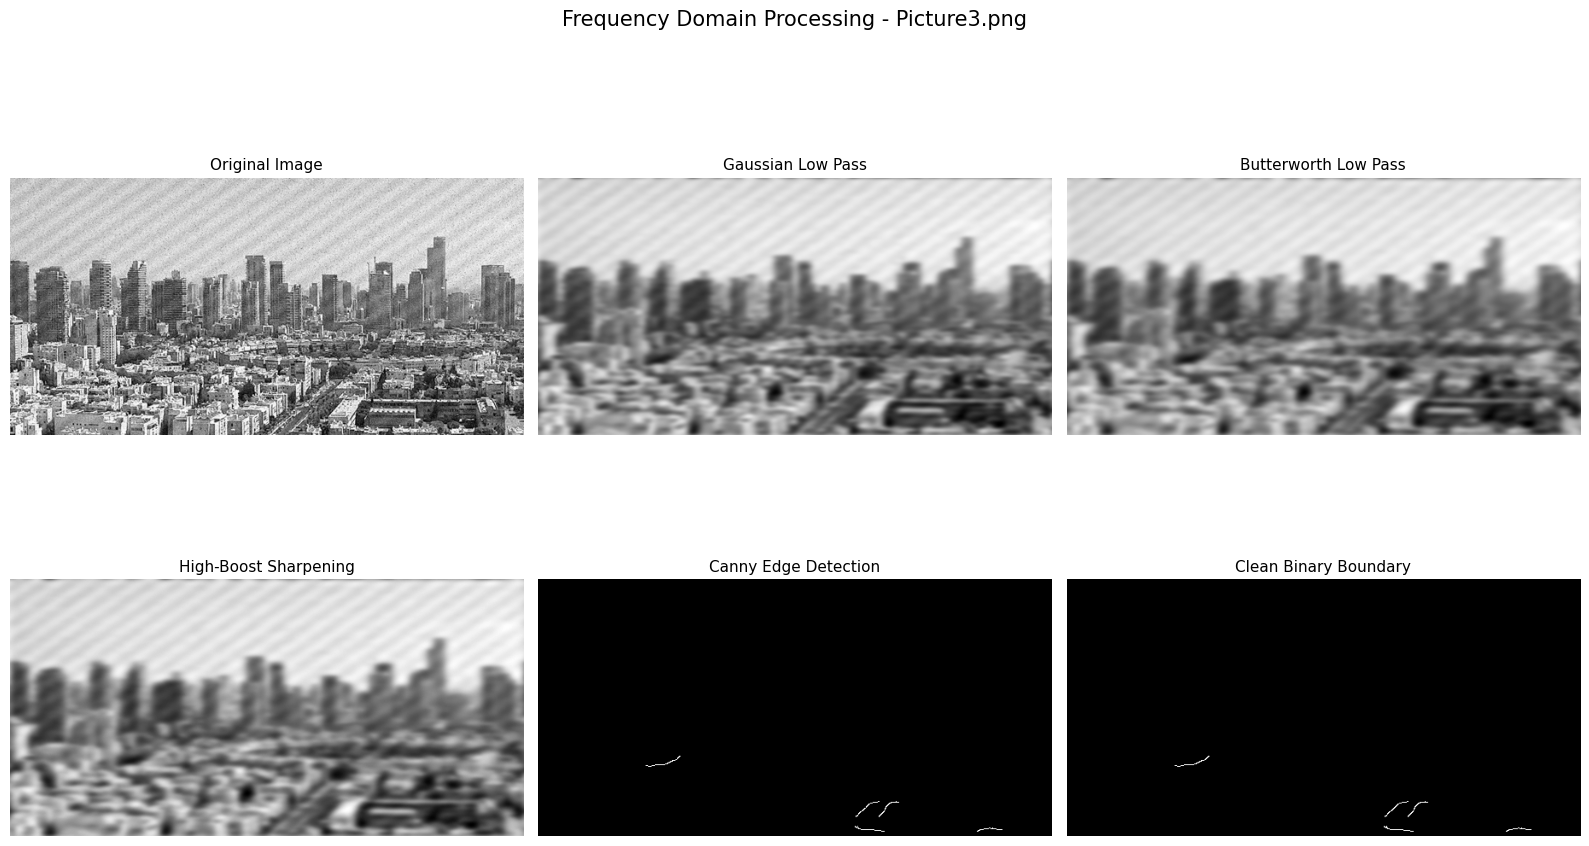

Completed: Picture3.png

Processing: Picture4.png


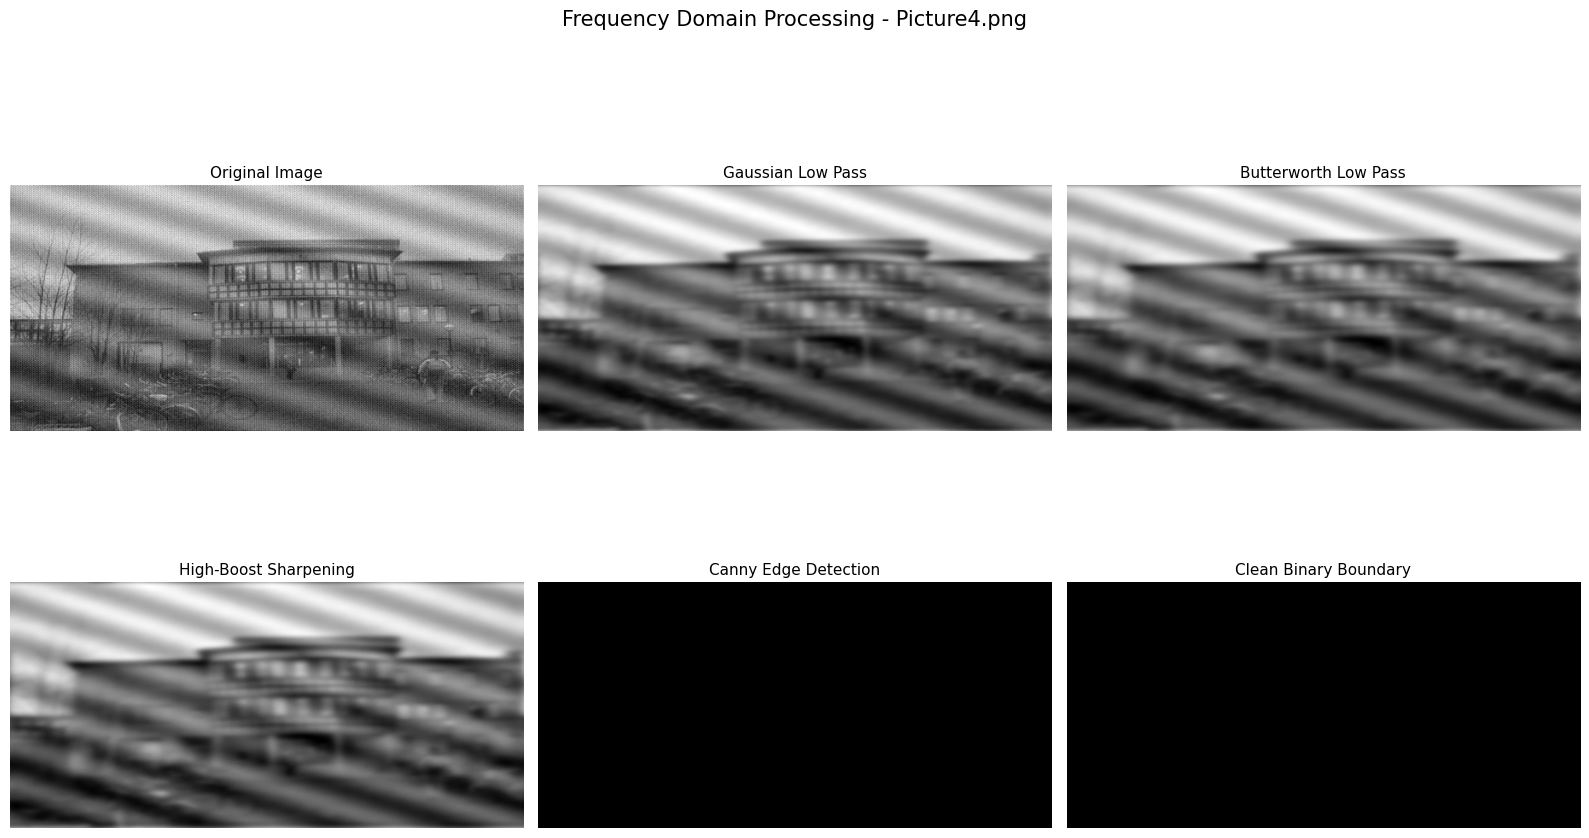

Completed: Picture4.png

Processing: Picture5.png


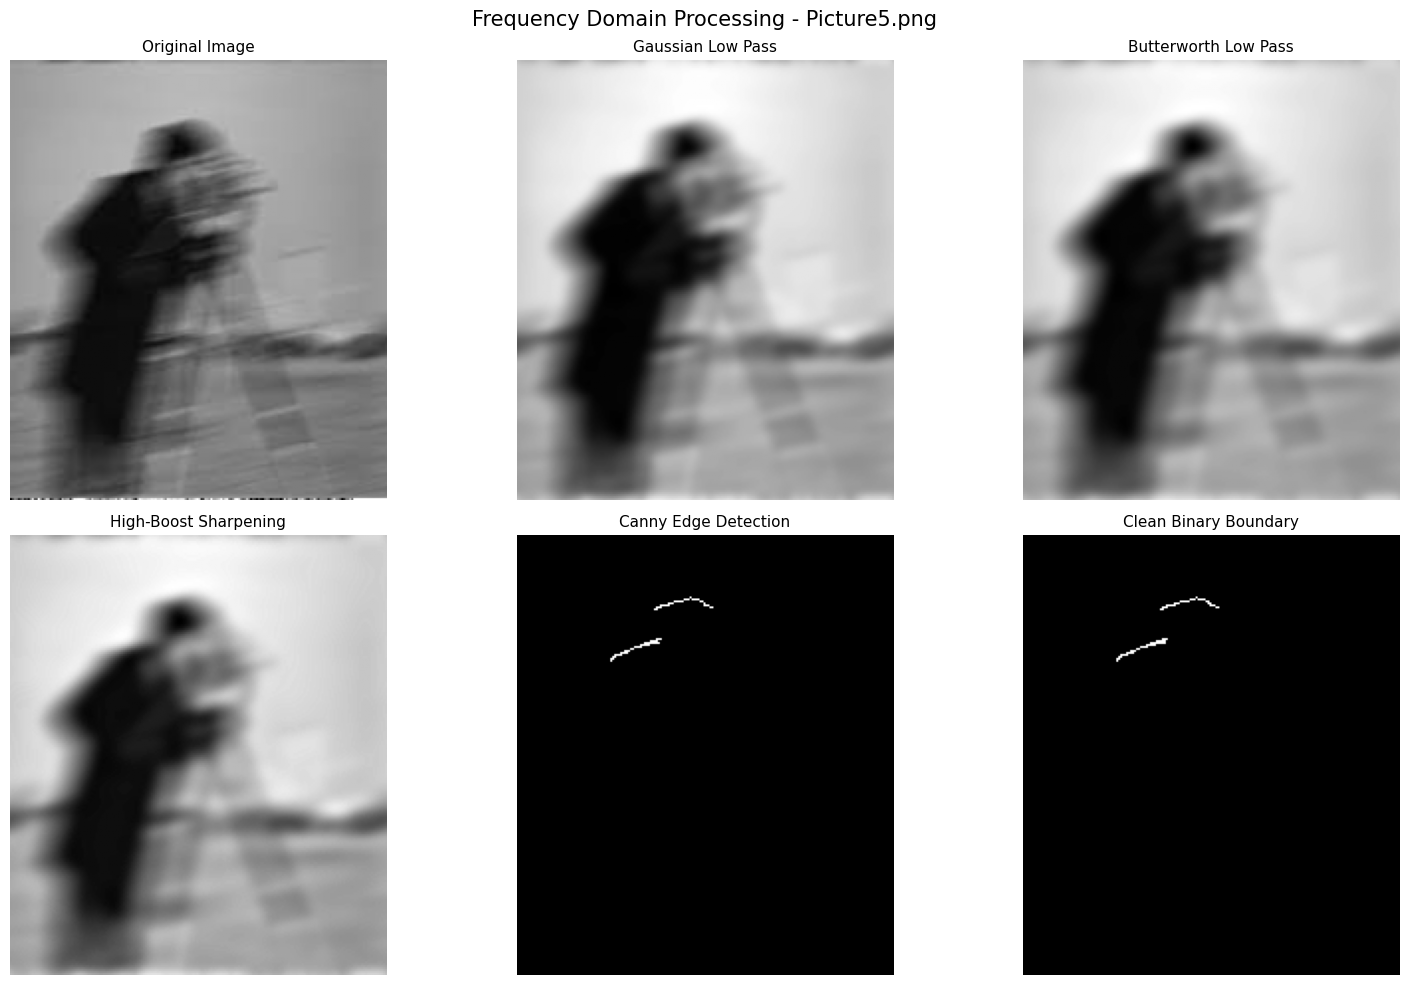

Completed: Picture5.png

QUANTITATIVE FILTER COMPARISON
 Mean Intensity  Contrast (Std)  Sharpness  Entropy  Edge Density (%)        Image          Method
         105.60           75.10    7614.75    7.548            28.687 Picture1.png        Original
         105.10           68.18      35.40    7.420             3.261 Picture1.png    Gaussian LPF
         105.10           68.70      26.52    7.427             2.484 Picture1.png Butterworth LPF
         104.60           69.60      40.71    7.465             4.067 Picture1.png      High-Boost
         155.35           74.36   22201.20    7.756            37.499 Picture2.png        Original
         154.86           45.26      20.05    7.310             4.743 Picture2.png    Gaussian LPF
         154.85           45.19      10.70    7.283             2.310 Picture2.png Butterworth LPF
         154.36           46.77      22.32    7.374             1.387 Picture2.png      High-Boost
         156.09           58.35    6292.16    7.591  

In [1]:

# ================================================================
# OPEN ENDED PROBLEM 10
# FREQUENCY DOMAIN IMAGE ENHANCEMENT AND BOUNDARY DETECTION
# ================================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# ------------------------------------------------
# STEP 1: FOLDER CONFIGURATION
# ------------------------------------------------

INPUT_FOLDER = Path.cwd()
OUTPUT_FOLDER = INPUT_FOLDER / "Output"

OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)

FILTER_FOLDER = OUTPUT_FOLDER / "Filtered_Images"
BOUNDARY_FOLDER = OUTPUT_FOLDER / "Boundary_Images"
COMPARISON_FOLDER = OUTPUT_FOLDER / "Comparisons"

FILTER_FOLDER.mkdir(exist_ok=True)
BOUNDARY_FOLDER.mkdir(exist_ok=True)
COMPARISON_FOLDER.mkdir(exist_ok=True)

# Input images
image_names = [
    "Picture1.png",
    "Picture2.png",
    "Picture3.png",
    "Picture4.png",
    "Picture5.png"
]

print("Input folder:", INPUT_FOLDER)
print("Output folder:", OUTPUT_FOLDER)

# ------------------------------------------------
# STEP 2: FREQUENCY DOMAIN FILTER FUNCTIONS
# ------------------------------------------------

def create_frequency_filters(rows, cols):

    center_y = rows // 2
    center_x = cols // 2

    y, x = np.ogrid[:rows, :cols]

    distance = np.sqrt(
        (x - center_x) ** 2 +
        (y - center_y) ** 2
    )

    cutoff = max(5, min(rows, cols) * 0.08)

    # Gaussian Low Pass Filter
    gaussian_filter = np.exp(
        -(distance ** 2) / (2 * cutoff ** 2)
    )

    # Butterworth Low Pass Filter
    order = 2

    butterworth_filter = 1 / (
        1 + (distance / cutoff) ** (2 * order)
    )

    return gaussian_filter, butterworth_filter


# ------------------------------------------------
# STEP 3: APPLY FREQUENCY DOMAIN FILTER
# ------------------------------------------------

def apply_frequency_filter(image, frequency_filter):

    image_float = np.float32(image)

    # Apply Fourier Transform
    dft = np.fft.fft2(image_float)

    # Shift zero frequency to center
    dft_shift = np.fft.fftshift(dft)

    # Apply frequency filter
    filtered_dft = dft_shift * frequency_filter

    # Inverse Fourier Transform
    inverse_shift = np.fft.ifftshift(filtered_dft)

    restored = np.fft.ifft2(inverse_shift)

    restored = np.real(restored)

    # Normalize output
    restored = np.clip(restored, 0, 255)

    return restored.astype(np.uint8)


# ------------------------------------------------
# STEP 4: FREQUENCY DOMAIN HIGH-BOOST SHARPENING
# ------------------------------------------------

def high_boost_sharpen(image, amount=0.7):

    rows, cols = image.shape

    gaussian_filter, _ = create_frequency_filters(
        rows, cols
    )

    # High-boost frequency transfer function
    high_boost_filter = (
        1 + amount * (1 - gaussian_filter)
    )

    # Apply high-boost filter
    image_float = np.float32(image)

    dft = np.fft.fft2(image_float)
    dft_shift = np.fft.fftshift(dft)

    sharpened_dft = dft_shift * high_boost_filter

    inverse_shift = np.fft.ifftshift(sharpened_dft)
    sharpened = np.fft.ifft2(inverse_shift)

    sharpened = np.real(sharpened)

    return np.clip(sharpened, 0, 255).astype(np.uint8)


# ------------------------------------------------
# STEP 5: BOUNDARY DETECTION
# ------------------------------------------------

def extract_boundaries(image):

    # Reduce small fluctuations before edge detection
    smoothed = cv2.GaussianBlur(
        image, (3, 3), 0
    )

    # Automatic Canny thresholds
    median_value = np.median(smoothed)

    lower_threshold = int(
        max(0, 0.66 * median_value)
    )

    upper_threshold = int(
        min(255, max(lower_threshold + 1,
                     1.33 * median_value))
    )

    # Detect object boundaries
    edges = cv2.Canny(
        smoothed,
        lower_threshold,
        upper_threshold
    )

    # Connect small gaps in boundaries
    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (3, 3)
    )

    clean_edges = cv2.morphologyEx(
        edges,
        cv2.MORPH_CLOSE,
        kernel,
        iterations=1
    )

    # Remove very small connected components
    number_labels, labels, stats, centroids = (
        cv2.connectedComponentsWithStats(
            clean_edges, connectivity=8
        )
    )

    final_boundary = np.zeros_like(clean_edges)

    for i in range(1, number_labels):

        area = stats[i, cv2.CC_STAT_AREA]

        if area >= 3:
            final_boundary[labels == i] = 255

    return edges, final_boundary


# ------------------------------------------------
# STEP 6: QUANTITATIVE IMAGE QUALITY METRICS
# ------------------------------------------------

def calculate_metrics(image, edges):

    # Mean intensity
    mean_intensity = np.mean(image)

    # Standard deviation
    contrast = np.std(image)

    # Laplacian variance (sharpness indicator)
    sharpness = cv2.Laplacian(
        image, cv2.CV_64F
    ).var()

    # Image entropy
    histogram = cv2.calcHist(
        [image], [0], None, [256], [0, 256]
    )

    probabilities = histogram.ravel()
    probabilities = probabilities / probabilities.sum()

    probabilities = probabilities[probabilities > 0]

    entropy = -np.sum(
        probabilities * np.log2(probabilities)
    )

    # Percentage of boundary pixels
    edge_density = (
        np.count_nonzero(edges) / edges.size
    ) * 100

    return {
        "Mean Intensity": round(float(mean_intensity), 2),
        "Contrast (Std)": round(float(contrast), 2),
        "Sharpness": round(float(sharpness), 2),
        "Entropy": round(float(entropy), 3),
        "Edge Density (%)": round(float(edge_density), 3)
    }


# ------------------------------------------------
# STEP 7: PROCESS ALL FIVE IMAGES
# ------------------------------------------------

all_metrics = []

for image_name in image_names:

    print("\n" + "=" * 55)
    print("Processing:", image_name)
    print("=" * 55)

    image_path = INPUT_FOLDER / image_name

    # Read image
    original = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    if original is None:
        print("WARNING: Image not found:", image_name)
        continue

    # Get image dimensions
    rows, cols = original.shape

    # Generate frequency filters
    gaussian_filter, butterworth_filter = (
        create_frequency_filters(rows, cols)
    )

    # ------------------------------------------------
    # A. GAUSSIAN LOW PASS FILTER
    # ------------------------------------------------

    gaussian_result = apply_frequency_filter(
        original,
        gaussian_filter
    )

    # ------------------------------------------------
    # B. BUTTERWORTH LOW PASS FILTER
    # ------------------------------------------------

    butterworth_result = apply_frequency_filter(
        original,
        butterworth_filter
    )

    # ------------------------------------------------
    # C. HIGH-BOOST SHARPENING
    # Applied to Butterworth-smoothed image
    # ------------------------------------------------

    sharpened = high_boost_sharpen(
        butterworth_result,
        amount=0.7
    )

    # ------------------------------------------------
    # D. BOUNDARY EXTRACTION
    # ------------------------------------------------

    raw_edges, final_boundary = extract_boundaries(
        sharpened
    )

    # ------------------------------------------------
    # STEP 8: SAVE PROCESSED IMAGES
    # ------------------------------------------------

    cv2.imwrite(
        str(FILTER_FOLDER / f"Gaussian_{image_name}"),
        gaussian_result
    )

    cv2.imwrite(
        str(FILTER_FOLDER / f"Butterworth_{image_name}"),
        butterworth_result
    )

    cv2.imwrite(
        str(FILTER_FOLDER / f"HighBoost_{image_name}"),
        sharpened
    )

    cv2.imwrite(
        str(BOUNDARY_FOLDER / f"RawEdges_{image_name}"),
        raw_edges
    )

    cv2.imwrite(
        str(BOUNDARY_FOLDER / f"FinalBoundary_{image_name}"),
        final_boundary
    )

    # ------------------------------------------------
    # STEP 9: CALCULATE METRICS
    # ------------------------------------------------

    versions = {
        "Original": original,
        "Gaussian LPF": gaussian_result,
        "Butterworth LPF": butterworth_result,
        "High-Boost": sharpened
    }

    for method, result in versions.items():

        if method == "Original":
            metric_edges = cv2.Canny(
                original, 50, 150
            )
        elif method == "Gaussian LPF":
            metric_edges = cv2.Canny(
                gaussian_result, 50, 150
            )
        elif method == "Butterworth LPF":
            metric_edges = cv2.Canny(
                butterworth_result, 50, 150
            )
        else:
            metric_edges = final_boundary

        metrics = calculate_metrics(
            result, metric_edges
        )

        metrics["Image"] = image_name
        metrics["Method"] = method

        all_metrics.append(metrics)

    # ------------------------------------------------
    # STEP 10: DISPLAY COMPARISON
    # ------------------------------------------------

    plt.figure(figsize=(16, 10))

    display_images = [
        original,
        gaussian_result,
        butterworth_result,
        sharpened,
        raw_edges,
        final_boundary
    ]

    display_titles = [
        "Original Image",
        "Gaussian Low Pass",
        "Butterworth Low Pass",
        "High-Boost Sharpening",
        "Canny Edge Detection",
        "Clean Binary Boundary"
    ]

    for index, (img, title) in enumerate(
        zip(display_images, display_titles)
    ):

        plt.subplot(2, 3, index + 1)

        plt.imshow(img, cmap="gray")
        plt.title(title, fontsize=11)
        plt.axis("off")

    plt.suptitle(
        f"Frequency Domain Processing - {image_name}",
        fontsize=15
    )

    plt.tight_layout()

    plt.savefig(
        str(COMPARISON_FOLDER /
            f"Comparison_{image_name}"),
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    print("Completed:", image_name)


# ------------------------------------------------
# STEP 11: GENERATE QUANTITATIVE REPORT
# ------------------------------------------------

if not all_metrics:

    raise FileNotFoundError(
        "No input images were processed. "
        "Check that Picture1.png to Picture5.png "
        "are in the current notebook folder."
    )

results_df = pd.DataFrame(all_metrics)

# Save quantitative results
csv_path = OUTPUT_FOLDER / "Filter_Comparison_Report.csv"

results_df.to_csv(csv_path, index=False)

print("\n" + "=" * 65)
print("QUANTITATIVE FILTER COMPARISON")
print("=" * 65)

print(results_df.to_string(index=False))


# ------------------------------------------------
# STEP 12: FINAL SUMMARY
# ------------------------------------------------

print("\n" + "=" * 65)
print("EXPERIMENT COMPLETED SUCCESSFULLY")
print("=" * 65)

print("Total images processed:", 
      len(set(results_df["Image"])))

print("Processed filters:")
print("1. Gaussian Low Pass Filter")
print("2. Butterworth Low Pass Filter")
print("3. Frequency Domain High-Boost Sharpening")
print("4. Canny Boundary Detection")
print("5. Morphological Boundary Cleanup")

print("\nAll results saved in:")
print(OUTPUT_FOLDER.resolve())
